# Square root of both previous-year and target grades

Compare **Baseline**, **Sqrt target only**, and **Sqrt both** across the same 20 train/test splits and nine regression models. The new condition replaces the previous-year predictor with its square root inside the model pipeline and fits the square root of the final-grade target. Predictions are squared back to grade points before tuning, scoring, and plotting.

The cohort, other predictors, hyperparameter grids, CV folds, and random seeds match the earlier square-root experiment. No weighting or resampling is used. Existing baseline/target-only checkpoints are reused when their data/configuration fingerprint matches; otherwise they are rebuilt. Four split workers run concurrently, with one thread per worker. Classification is not fitted.

Square-root predictions are truncated at zero before squaring, as in the previous experiment; no upper clipping or retransformation bias correction is applied. Shared grade units do not guarantee that transforming both will help: this experiment measures the effect.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

# Identical complete-case cohort and income preprocessing to the earlier experiment.
df = pd.read_csv('student_grade_ses_dataset.csv').drop_duplicates().set_index('student_id').dropna()
df['log_income'] = np.log(df.pop('annual_family_income_inr'))
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'log_income'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)
from sqrt_both_experiment import ONEHOT_COLUMNS, ORDINAL_COLUMNS
schema = {key: globals()[key] for key in [
    'CONTINUOUS_COLS', 'NUMERIC_COLS', 'PREDICTOR_COLS', 'ONEHOT_COLUMNS', 'ORDINAL_COLUMNS']}
assert np.isfinite(X['previous_year_grade_pct']).all()
assert X['previous_year_grade_pct'].between(0, 100).all()
assert Y_regression.between(0, 100).all()
print(f'{len(X):,} students; {len(X.columns)} predictors')

Dropped: ['age', 'num_siblings']
X: (8785, 22)


8,785 students; 22 predictors


## What changes in the new condition?

Only `previous_year_grade_pct` changes among the predictors; it is square-root transformed before any model-specific scaling or encoding. Both target transformations are handled by `TransformedTargetRegressor`, so cross-validation uses errors on the original 0–100 scale. The plot below shows the relationship before and after transforming both axes.

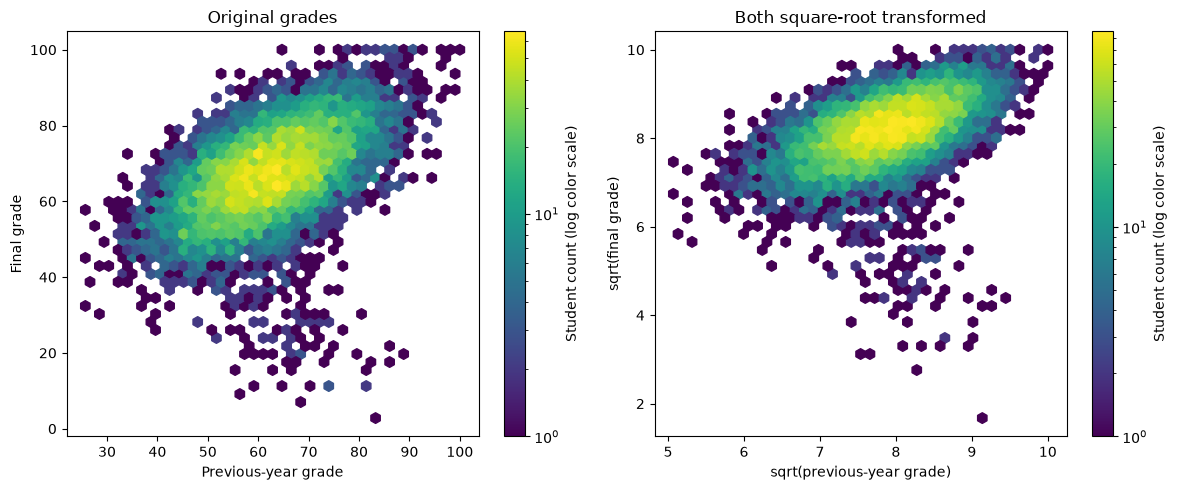

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, transformed in zip(axes, [False, True]):
    x = np.sqrt(X['previous_year_grade_pct']) if transformed else X['previous_year_grade_pct']
    y = np.sqrt(Y_regression) if transformed else Y_regression
    points = ax.hexbin(x, y, gridsize=40, mincnt=1, bins='log', cmap='viridis')
    ax.set(xlabel='sqrt(previous-year grade)' if transformed else 'Previous-year grade',
           ylabel='sqrt(final grade)' if transformed else 'Final grade',
           title='Both square-root transformed' if transformed else 'Original grades')
    fig.colorbar(points, ax=ax, label='Student count (log color scale)')
plt.tight_layout()
plt.show()

## Paired experiments

Baseline and target-only runs use their original pipeline. The new both-transformed condition is tuned independently, using the same folds. Checkpoints are saved after each split so interrupted runs can resume.

In [3]:
import time, json, platform, importlib.metadata
import sqrt_experiment as target_experiment
import sqrt_both_experiment as both_experiment

NUMBER_OF_EXPERIMENTS = 20
N_JOBS = 4
SMOKE = False
if SMOKE:
    # Include enough rare F grades to exercise the subgroup plots in a short run.
    failing = df.loc[X.index, CLASSIFICATION_TARGET].eq('F')
    X = pd.concat([X.loc[failing].sample(n=40, random_state=42),
                   X.loc[~failing].sample(n=200, random_state=42)])
    Y_regression = Y_regression.loc[X.index]
bands = df[CLASSIFICATION_TARGET].loc[X.index]
start = time.perf_counter()
previous_results, previous_directory = target_experiment.run_experiments(
    X, Y_regression, bands, schema, n_splits=NUMBER_OF_EXPERIMENTS, n_jobs=N_JOBS, smoke=SMOKE)
results, result_directory = both_experiment.run_experiments(
    X, Y_regression, bands, schema, n_splits=NUMBER_OF_EXPERIMENTS, n_jobs=N_JOBS, smoke=SMOKE)
elapsed_seconds = time.perf_counter() - start

# Validate the retained first split's raw data before combining the checkpoints.
for key in ['X_train', 'X_test', 'y_train', 'y_test']:
    left, right = previous_results[0]['data'][key], results[0]['data'][key]
    assert left.equals(right), f'Different raw split data: {key}'

all_results = previous_results + results
predictions = pd.concat([frame for result in all_results for frame in result['predictions']], ignore_index=True)
metrics = pd.DataFrame([row for result in all_results for row in result['metrics']])
timings = pd.DataFrame([row for result in all_results for row in result['timings']])
for frame in [predictions, metrics, timings]:
    frame['condition'] = frame['condition'].replace({'Sqrt': 'Sqrt target only'})
conditions = ['Baseline', 'Sqrt target only', 'Sqrt both']
models = target_experiment.NAMES
assert np.isfinite(predictions[['actual', 'predicted']]).all().all()
# Every condition/model must predict exactly the same held-out students in each split.
for experiment, split in predictions.groupby('experiment'):
    reference = split[(split['condition']=='Baseline') & (split['model']=='OLS')].set_index('student_id')['actual'].sort_index()
    for _, group in split.groupby(['condition', 'model']):
        pd.testing.assert_series_equal(group.set_index('student_id')['actual'].sort_index(), reference)

f_errors = (predictions[predictions['grade band']=='F']
    .assign(**{'F MAE': lambda p: (p['predicted']-p['actual']).abs(),
               'F overprediction': lambda p: p['predicted']-p['actual']})
    .groupby(['experiment', 'condition', 'model'])
    .agg(**{'F MAE': ('F MAE', 'mean'), 'F overprediction': ('F overprediction', 'mean'),
            'F support': ('actual', 'size')}).reset_index())
comparison = metrics.merge(f_errors, on=['experiment', 'condition', 'model'], how='left', validate='one_to_one')
comparison['F support'] = comparison['F support'].fillna(0).astype(int)
for name, frame in [('predictions', predictions), ('metrics', metrics), ('timings', timings), ('comparison', comparison)]:
    frame.to_csv(result_directory/(name+'.csv'), index=False)
manifest = dict(splits=NUMBER_OF_EXPERIMENTS, workers=N_JOBS, smoke=SMOKE,
    previous_results=str(previous_directory), elapsed_seconds=elapsed_seconds,
    transform_predictor='sqrt(previous_year_grade_pct)', transform_target='sqrt(final_grade_pct)',
    inverse='maximum(z, 0) ** 2', scoring='original-grade RMSE', upper_clip=False,
    python=platform.python_version(),
    versions={name: importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','pygam','joblib']},
    grids=both_experiment.GRIDS)
(result_directory/'manifest.json').write_text(json.dumps(manifest, indent=2))
print(f'Completed {NUMBER_OF_EXPERIMENTS} paired splits in {elapsed_seconds/60:.1f} minutes. Results: {result_directory}')
summary = comparison.groupby(['model', 'condition'])[['RMSE','MAE','F MAE']].mean()
display(summary.reindex(pd.MultiIndex.from_product([models, conditions], names=['model','condition'])).round(3))

Split 2: restored checkpoint
Split 3: restored checkpoint
Split 4: restored checkpoint
Split 1: restored checkpoint
Split 5: restored checkpoint
Split 6: restored checkpoint
Split 7: restored checkpoint
Split 8: restored checkpoint
Split 9: restored checkpoint
Split 10: restored checkpoint


Split 11: restored checkpoint
Split 12: restored checkpoint
Split 13: restored checkpoint
Split 14: restored checkpoint
Split 15: restored checkpoint
Split 16: restored checkpoint
Split 17: restored checkpoint
Split 18: restored checkpoint
Split 19: restored checkpoint
Split 20: restored checkpoint


Split 1: Sqrt both complete


Split 4: Sqrt both complete


Split 2: Sqrt both complete


Split 3: Sqrt both complete


... (14 outputs left out)

Split 20: Sqrt both complete


Split 19: Sqrt both complete


Completed 20 paired splits in 5.6 minutes. Results: sqrt-both-results/fc2e9eeb594d255b


RMSE    MAE   F MAE
model condition                              
Naive Baseline          11.635  8.932  37.739
      Sqrt target only  11.649  8.961  37.171
      Sqrt both         11.649  8.961  37.171
OLS   Baseline           9.533  7.000  35.822
      Sqrt target only   9.548  7.034  35.509
      Sqrt both          9.547  7.037  35.398
Ridge Baseline           9.531  6.998  35.849
      Sqrt target only   9.545  7.032  35.536
      Sqrt both          9.544  7.034  35.426
Lasso Baseline           9.529  6.995  35.884
      Sqrt target only   9.542  7.027  35.545
      Sqrt both          9.541  7.029  35.434
GAM   Baseline           9.539  7.000  35.817
      Sqrt target only   9.554  7.037  35.447
      Sqrt both          9.554  7.038  35.414
k-NN  Baseline           9.991  7.458  36.320
      Sqrt target only  10.038  7.518  35.880
      Sqrt both         10.040  7.515  35.854
DT    Baseline          10.013  7.449  36.151
      Sqrt target only  10.039  7.468  35.917
      Sqrt both         10.039  7.468  35.917
RF    Baseline           9.695  7.144  36.121
      Sqrt target only   9.711  7.182  35.693
      Sqrt both          9.710  7.182  35.696
GBT   Baseline           9.628  7.086  36.078
      Sqrt target only   9.650  7.126  35.698
      Sqrt both          9.650  7.126  35.698

## Does transforming the predictor add value?

All errors below are measured in grade points. Negative changes indicate lower error. Each box contains paired differences across the repeated splits; these splits overlap, so the boxes describe variability rather than independent confidence intervals.

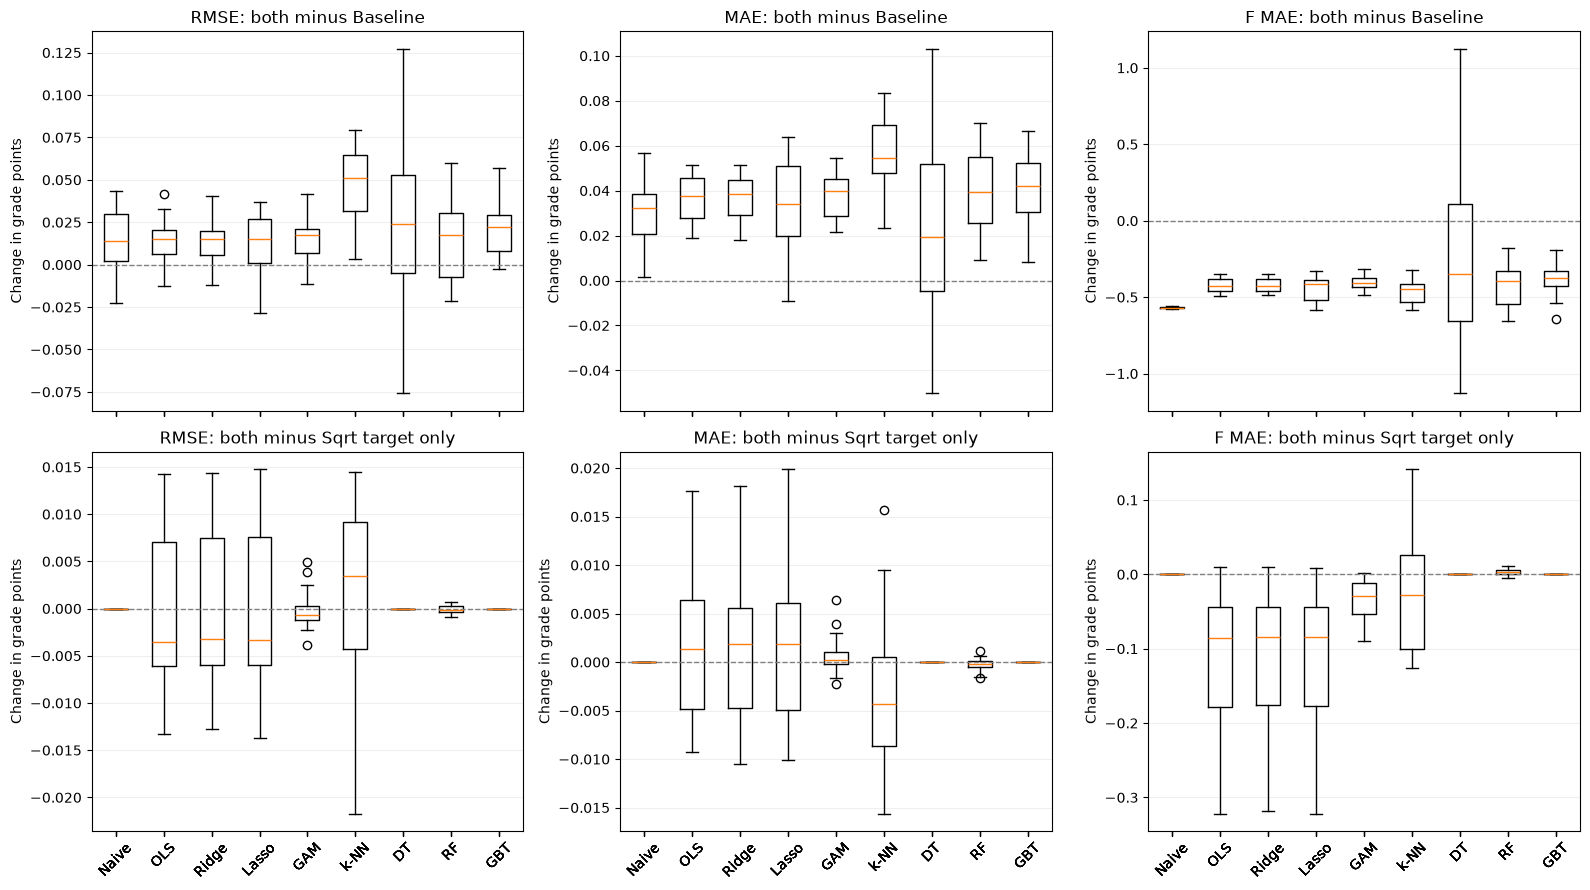

metric                   F MAE     MAE    RMSE
reference        model                        
Baseline         DT    -0.2341  0.0185  0.0265
                 GAM   -0.4032  0.0379  0.0149
                 GBT   -0.3806  0.0401  0.0219
                 Lasso -0.4499  0.0338  0.0120
                 Naive -0.5680  0.0293  0.0135
                 OLS   -0.4241  0.0364  0.0138
                 RF    -0.4246  0.0379  0.0152
                 Ridge -0.4231  0.0362  0.0135
                 k-NN  -0.4664  0.0566  0.0483
Sqrt target only DT     0.0000  0.0000  0.0000
                 GAM   -0.0335  0.0006 -0.0002
                 GBT    0.0000  0.0000  0.0000
                 Lasso -0.1109  0.0023 -0.0012
                 Naive  0.0000  0.0000  0.0000
                 OLS   -0.1117  0.0022 -0.0013
                 RF     0.0034 -0.0003 -0.0001
                 Ridge -0.1102  0.0023 -0.0011
                 k-NN  -0.0261 -0.0036  0.0013

**Mean results over 20 splits.** Compared with transforming the target only, transforming both reduced overall RMSE for 5 of 9 models and F-grade MAE for 5 of 9 models. Compared with the original baseline, the corresponding counts are 0 and 9. Use the magnitude of the changes as well as their direction; F-grade errors can remain large.

In [4]:
wide = comparison.pivot(index=['experiment','model'], columns='condition', values=['RMSE','MAE','F MAE'])
delta_records = []
for reference in ['Baseline', 'Sqrt target only']:
    for metric in ['RMSE','MAE','F MAE']:
        delta = wide[(metric, 'Sqrt both')] - wide[(metric, reference)]
        delta_records.append(delta.rename('change').reset_index().assign(metric=metric, reference=reference))
deltas = pd.concat(delta_records, ignore_index=True)
deltas.to_csv(result_directory/'paired-changes.csv', index=False)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
for row, reference in enumerate(['Baseline', 'Sqrt target only']):
    for ax, metric in zip(axes[row], ['RMSE','MAE','F MAE']):
        values = deltas[(deltas['reference']==reference) & (deltas['metric']==metric)]
        ax.boxplot([values.loc[values['model']==model, 'change'] for model in models], tick_labels=models)
        ax.axhline(0, color='grey', linestyle='--', linewidth=1)
        ax.set(title=f'{metric}: both minus {reference}', ylabel='Change in grade points')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()
fig.savefig(result_directory/'paired-changes.png', dpi=160, bbox_inches='tight')

change_summary = deltas.groupby(['reference','model','metric'])['change'].mean().unstack('metric')
display(change_summary.round(4))
vs_target = change_summary.loc['Sqrt target only']
vs_baseline = change_summary.loc['Baseline']
display(Markdown(
    f"**Mean results over {NUMBER_OF_EXPERIMENTS} splits.** Compared with transforming the target only, "
    f"transforming both reduced overall RMSE for {(vs_target['RMSE'] < 0).sum()} of {len(models)} models "
    f"and F-grade MAE for {(vs_target['F MAE'] < 0).sum()} of {len(models)} models. "
    f"Compared with the original baseline, the corresponding counts are "
    f"{(vs_baseline['RMSE'] < 0).sum()} and {(vs_baseline['F MAE'] < 0).sum()}. "
    "Use the magnitude of the changes as well as their direction; F-grade errors can remain large."))

## Predicted versus actual grades

The same held-out students from split 0 appear in every panel. Red points mark F-grade students. The diagonal represents perfect predictions. Four representative model families are shown; the exported results contain all nine models.

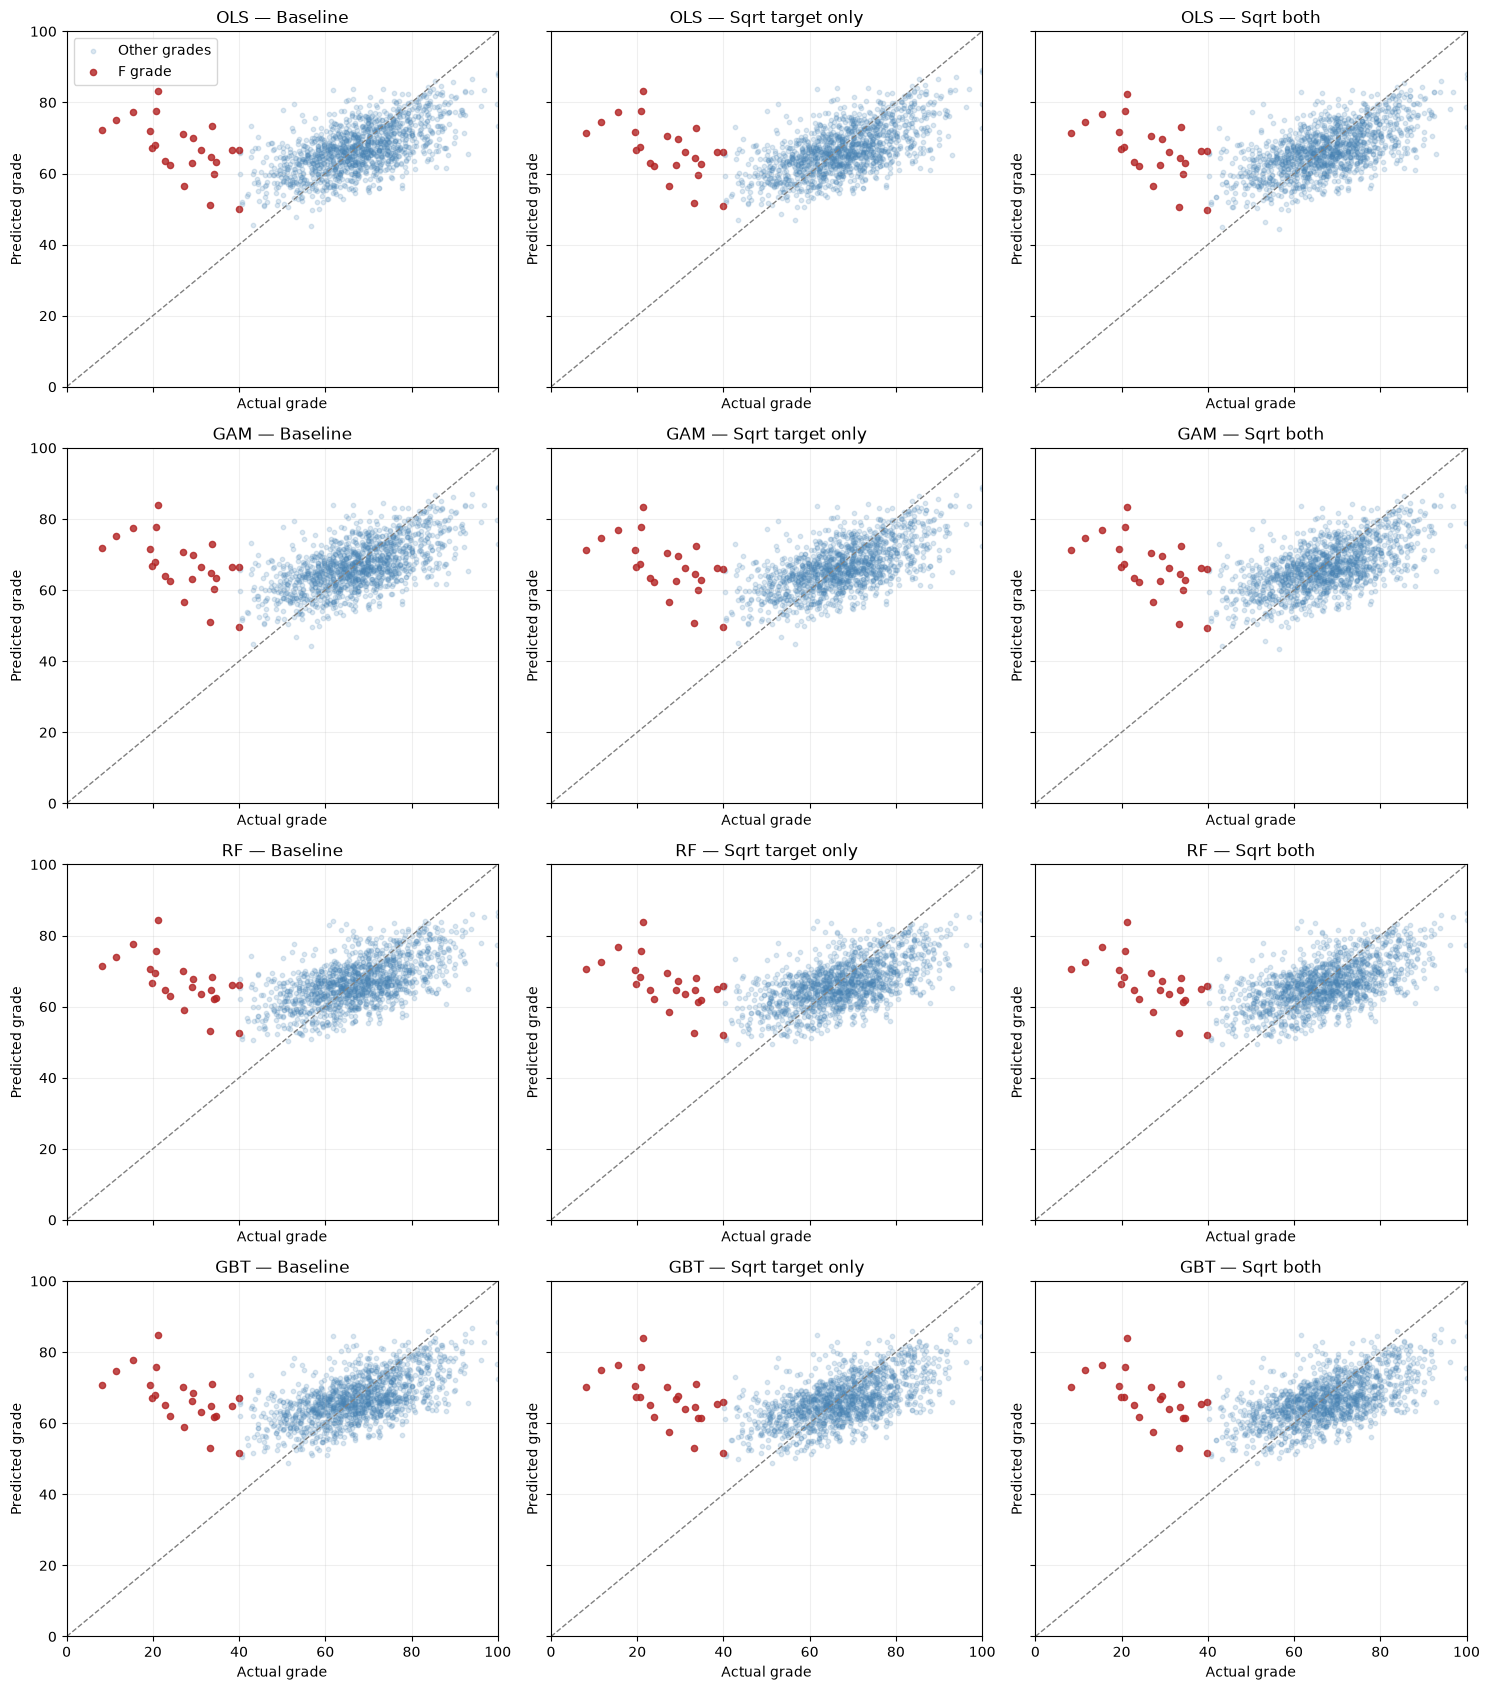

In [5]:
selected_models = ['OLS','GAM','RF','GBT']
first = predictions[predictions['experiment']==0]
fig, axes = plt.subplots(len(selected_models), len(conditions), figsize=(15, 17), sharex=True, sharey=True)
for row, model in enumerate(selected_models):
    for ax, condition in zip(axes[row], conditions):
        points = first[(first['model']==model) & (first['condition']==condition)]
        failing = points['grade band']=='F'
        ax.scatter(points.loc[~failing,'actual'], points.loc[~failing,'predicted'], s=10, alpha=.18, color='steelblue', label='Other grades')
        ax.scatter(points.loc[failing,'actual'], points.loc[failing,'predicted'], s=20, alpha=.8, color='firebrick', label='F grade')
        ax.plot([0,100], [0,100], '--', color='grey', linewidth=1)
        ax.set(xlim=(0,100), ylim=(0,100), title=f'{model} — {condition}',
               xlabel='Actual grade', ylabel='Predicted grade')
        ax.grid(alpha=.2)
axes[0,0].legend()
plt.tight_layout()
plt.show()
fig.savefig(result_directory/'predicted-actual.png', dpi=160, bbox_inches='tight')

## Error across grade bands

Mean absolute error is computed within each grade band and split, then averaged across splits. This checks whether any improvement among F-grade students comes with larger errors elsewhere.

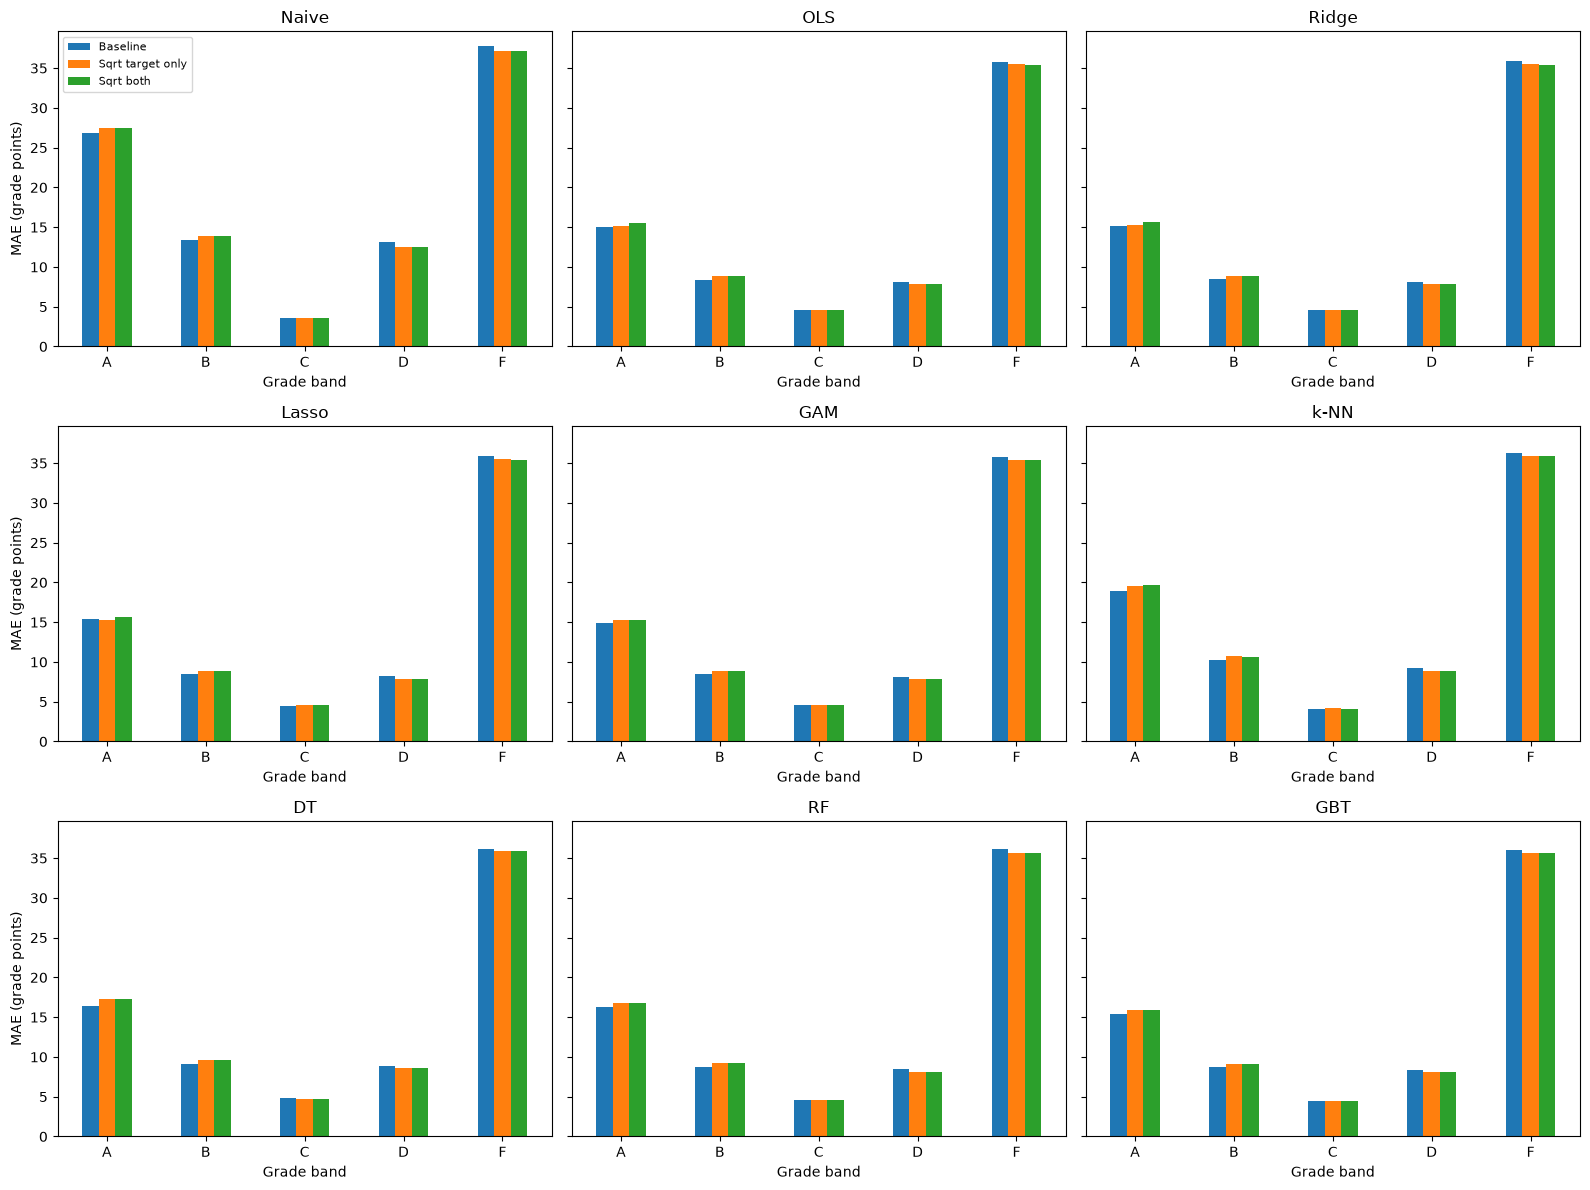

In [6]:
grade_errors = (predictions.assign(absolute_error=lambda p: (p['predicted']-p['actual']).abs())
    .groupby(['experiment','model','condition','grade band'])['absolute_error'].mean().reset_index())
grade_errors.to_csv(result_directory/'grade-band-errors.csv', index=False)
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharey=True)
for ax, model in zip(axes.flat, models):
    table = (grade_errors[grade_errors['model']==model]
        .groupby(['grade band','condition'])['absolute_error'].mean().unstack('condition')
        .reindex(columns=conditions))
    table.plot.bar(ax=ax, rot=0, legend=False)
    ax.set(title=model, ylabel='MAE (grade points)', xlabel='Grade band')
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()